# 🏨 Hotel Booking Cancellation Predictor

**Who has the problem?** A hotel's revenue-management team. Last-minute cancellations leave rooms empty and cost revenue.

**Decision the model supports:** how much to overbook, and whether to ask for a deposit (none / partial / full) at booking time.

**Target:** `is_canceled` (1 = cancelled, 0 = not cancelled).

**Which metric matters, and why:**
- Missing a cancellation (false negative) = an empty room and lost revenue.
- A false alarm (false positive) = an unnecessary deposit request, or overbooking that forces us to relocate a guest.
- About 72% of bookings are *not* cancelled, so a model that always says "not cancelled" already scores ~72% accuracy. **Accuracy is misleading here.**
- Main metrics: **Recall, Precision, F1 and PR-AUC** (ROC-AUC as a secondary view). The decision threshold is chosen on the training data only.

**Data:** *Hotel Booking Demand*, Kaggle, licence CC BY 4.0. Two hotels in Portugal (a city hotel and a resort), arrivals 2015–2017.
https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
Original paper: Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief.

**Notebook outline:** 1. Data loading → 2. Data understanding → 3. Cleaning → 4. Leakage → 5. Feature engineering & split → 6. EDA → 7. Pipeline → 8. Models & CV → 9. Tuning & threshold → 10. Test evaluation → 11. Error analysis → 12. Business recommendation & limitations → 13. Save model for the app.

## 1. Data loading
The data is downloaded with the Kaggle API (needs a `KAGGLE_API_TOKEN` secret in Colab). Alternative: download `hotel_bookings.csv` from the Kaggle page and upload it manually.

In [1]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q --upgrade kaggle
!kaggle datasets download -d jessemostipak/hotel-booking-demand
!unzip -o hotel-booking-demand.zip

Dataset URL: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.25M/1.25M [00:00<00:00, 141MB/s]

Archive:  hotel-booking-demand.zip
  inflating: hotel_bookings.csv      


## 2. Data understanding
- **Size:** 119,390 rows × 32 columns. Data types: 16 integer, 4 float, 12 text columns.
- **Target balance (raw):** 37.0% cancelled, 63.0% not cancelled.
- **Missing values:** `company` 112,593 (94%), `agent` 16,340, `country` 488, `children` 4.
  - Missing `company` / `agent` most likely means "no company / no agent", so they are treated as a category, not imputed.
- **Duplicates:** 31,994 rows (~27%).

**Why this matters:** duplicate rows could put the same booking in both the training and the test set, which would make the scores look better than they really are. The missing `company` and `agent` values carry meaning (no company / no agent), so they are encoded as a category instead of being imputed.

The column dictionary (with meanings) is in section 4.

In [2]:
import pandas as pd, numpy as np
df = pd.read_csv("hotel_bookings.csv")
print(df.shape)
df.info()
print(df["is_canceled"].value_counts(normalize=True))
print(df.isna().sum().sort_values(ascending=False).head())
print("duplicates:", df.duplicated().sum())

(119390, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  mea

## 3. Cleaning
**Duplicates.** If identical rows are kept, the same booking can land in both train and test, and the score looks better than it really is. All 31,994 duplicate rows were removed (a conservative choice; a few may be genuinely separate identical bookings).

In [3]:
# 1) Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicates -> {len(df)} rows left")

# 2) Class balance after cleaning
print(df["is_canceled"].value_counts(normalize=True))

# 3) Look at the leakage columns
print(df["reservation_status"].value_counts())
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))

Removed 31994 duplicates -> 87396 rows left
is_canceled
0    0.725102
1    0.274898
Name: proportion, dtype: float64
reservation_status
Check-Out    63371
Canceled     23011
No-Show       1014
Name: count, dtype: int64
is_canceled             0      1
reservation_status              
Canceled                0  23011
Check-Out           63371      0
No-Show                 0   1014


In [4]:
print(df[["adr","lead_time"]].describe())
print("negative adr:", (df["adr"] < 0).sum())
print("adr > 1000:", (df["adr"] > 1000).sum())
print("zero guests:", ((df["adults"] + df["children"].fillna(0) + df["babies"]) == 0).sum())
print("zero nights:", ((df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0).sum())

                adr     lead_time
count  87396.000000  87396.000000
mean     106.337246     79.891368
std       55.013953     86.052325
min       -6.380000      0.000000
25%       72.000000     11.000000
50%       98.100000     49.000000
75%      134.000000    125.000000
max     5400.000000    737.000000
negative adr: 1
adr > 1000: 1
zero guests: 166
zero nights: 651


In [5]:
# فحص الصفوف اللي ليالي = 0
zero_nights = (df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0
print(df[zero_nights]["is_canceled"].value_counts(normalize=True))
print(df[zero_nights]["market_segment"].value_counts().head())

# تنضيف
guests = df["adults"] + df["children"].fillna(0) + df["babies"]
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
mask = (df["adr"] >= 0) & (df["adr"] <= 1000) & (guests > 0) & (nights > 0)
print("rows removed:", (~mask).sum())
df = df[mask].reset_index(drop=True)
print(df.shape)
print(df["is_canceled"].value_counts(normalize=True))

is_canceled
0    0.955453
1    0.044547
Name: proportion, dtype: float64
market_segment
Online TA        297
Direct           131
Offline TA/TO    122
Corporate         47
Groups            34
Name: count, dtype: int64
rows removed: 759
(86637, 32)
is_canceled
0    0.723155
1    0.276845
Name: proportion, dtype: float64


### Cleaning decisions
| Issue | Rows | Decision | Why |
|---|---|---|---|
| Negative `adr` | 1 | removed | impossible price |
| `adr` = 5,400 (75% of bookings are below 134) | 1 | removed | extreme outlier |
| Zero guests | 166 | removed | not a real booking |
| Zero nights | 651 | removed | 95.5% of them are *not* cancelled, so they look like day-use / special cases, not normal stays |

- Rows removed in this step: **759**. Remaining: **86,637** rows.
- Cancellation rate after cleaning: **27.7%**. The baseline accuracy (always "not cancelled") is therefore about **72%**.
- `lead_time` (max 737 days) was kept: long lead times are plausible (groups, companies) and tree models are robust to them.
- **Scope:** the model is built for normal stays of at least one night.

## 4. Leakage: only use what is known at booking time
The model must predict at the moment of booking, so any column that is only known **after** that moment must go.

The table below proves it for `reservation_status`: *Canceled* (23,011) and *No-Show* (1,014) always have `is_canceled = 1`, and *Check-Out* (63,371) always has `is_canceled = 0`. The column **is** the answer.

| Dropped column | Reason |
|---|---|
| `reservation_status` | the target in disguise |
| `reservation_status_date` | date of the final status, known only after the event |
| `assigned_room_type` | assigned at check-in |
| `booking_changes` | can change after the booking was made |

One more suspected leakage column (`required_car_parking_spaces`) is handled after the EDA, in section 7.

### Data dictionary
| Column | Meaning |
|---|---|
| `hotel` | City Hotel or Resort Hotel |
| `is_canceled` | **target**: 1 if the booking was cancelled |
| `lead_time` | days between booking date and arrival date |
| `arrival_date_year` / `_month` / `_week_number` / `_day_of_month` | arrival date parts |
| `stays_in_weekend_nights` / `stays_in_week_nights` | booked weekend / weekday nights |
| `adults` / `children` / `babies` | number of guests of each type |
| `meal` | meal plan (BB, HB, FB, SC = no meal package, Undefined) |
| `country` | guest country (code) |
| `market_segment` | market segment (TA = travel agents, TO = tour operators) |
| `distribution_channel` | booking channel |
| `is_repeated_guest` | 1 if the guest stayed before |
| `previous_cancellations` | earlier bookings this guest cancelled |
| `previous_bookings_not_canceled` | earlier bookings this guest did not cancel |
| `reserved_room_type` | room type code reserved |
| `deposit_type` | No Deposit / Non Refund / Refundable |
| `agent` | ID of the travel agency (missing = none) |
| `company` | ID of the paying company (missing = none) |
| `days_in_waiting_list` | days the booking waited before confirmation |
| `customer_type` | Transient, Contract, Group, Transient-Party |
| `adr` | average daily rate (revenue per night) |
| `required_car_parking_spaces` | parking spaces requested |
| `total_of_special_requests` | number of special requests |

In [6]:
# 1) Leakage columns
leak_cols = ["reservation_status", "reservation_status_date",
             "assigned_room_type", "booking_changes"]
df = df.drop(columns=leak_cols)
print(df.shape)

# 2) Data dictionary skeleton
dd = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
dd

(86637, 28)


,dtype,n_missing,n_unique,example
hotel,object,0,2,Resort Hotel
is_canceled,int64,0,2,0
lead_time,int64,0,478,7
arrival_date_year,int64,0,3,2015
arrival_date_month,object,0,12,July
arrival_date_week_number,int64,0,53,27
arrival_date_day_of_month,int64,0,31,1
stays_in_weekend_nights,int64,0,17,0
stays_in_week_nights,int64,0,33,1
adults,int64,0,14,1


## 5. Feature engineering and train/test split
Row-wise features (no statistics are learned from the data, so doing them before the split causes no leakage):
- `total_nights`, `total_guests`, `has_kids`
- `agent`: missing → `"0"` (no agent); `company`: 1 if a company is present, else 0
- `arrival_month` as a number; `arrival_date_year` dropped (only 3 values, it cannot generalise to future years)

**Split:** 80% train / 20% test, stratified on the target, **before** any imputing, scaling or encoding. Train: 69,309 rows. Test: 17,328 rows. Cancellation rate is 0.277 in both. The test set is used only once, at the end.

In [7]:
# نحتفظ بالسنة لو حبيت تعمل split زمني اختياري بعدين
arrival_year = df["arrival_date_year"].copy()

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]
df["has_kids"]     = ((df["children"].fillna(0) + df["babies"]) > 0).astype(int)
df["agent"]        = df["agent"].fillna(0).astype(int).astype(str)   # "0" = no agent
df["company"]      = df["company"].notna().astype(int)               # has company or not

months = {m: i for i, m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], 1)}
df["arrival_month"] = df["arrival_date_month"].map(months)
df = df.drop(columns=["arrival_date_month", "arrival_date_year"])

from sklearn.model_selection import train_test_split
X = df.drop(columns="is_canceled")
y = df["is_canceled"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("train:", X_train.shape, "| test:", X_test.shape)
print("cancel rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

# من هنا الـ EDA على الـ train بس
train_df = X_train.assign(is_canceled=y_train)

train: (69309, 29) | test: (17328, 29)
cancel rate train: 0.277 | test: 0.277


## 6. Exploratory data analysis (training data only)
All EDA below uses the **training set only**, so no decision is influenced by the test set.

### 6.1 Univariate

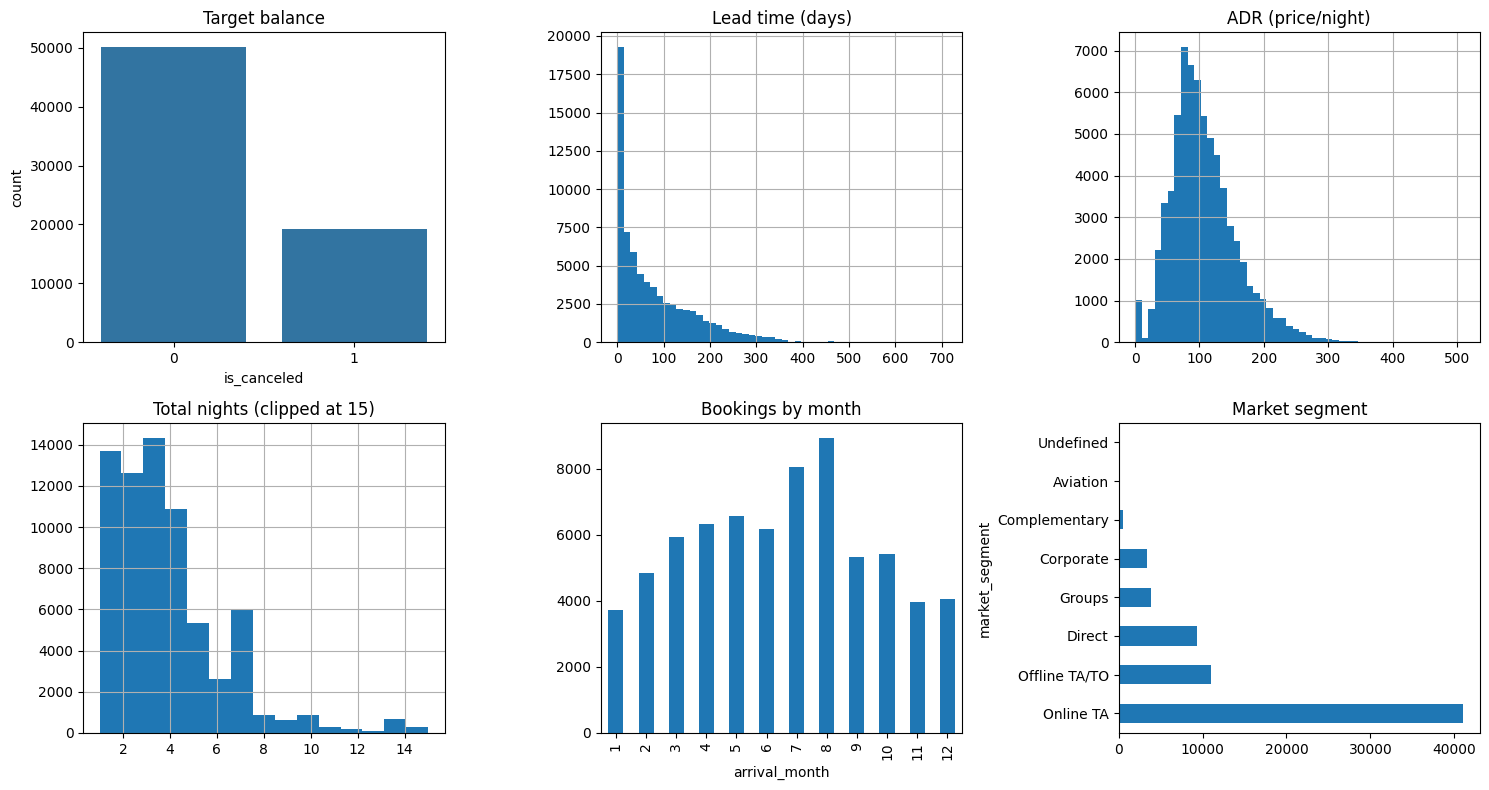

In [8]:
import seaborn as sns, matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x="is_canceled", data=train_df, ax=ax[0,0]); ax[0,0].set_title("Target balance")
train_df["lead_time"].hist(bins=50, ax=ax[0,1]);            ax[0,1].set_title("Lead time (days)")
train_df["adr"].hist(bins=50, ax=ax[0,2]);                  ax[0,2].set_title("ADR (price/night)")
train_df["total_nights"].clip(upper=15).hist(bins=15, ax=ax[1,0]); ax[1,0].set_title("Total nights (clipped at 15)")
train_df["arrival_month"].value_counts().sort_index().plot.bar(ax=ax[1,1]); ax[1,1].set_title("Bookings by month")
train_df["market_segment"].value_counts().plot.barh(ax=ax[1,2]); ax[1,2].set_title("Market segment")
plt.tight_layout(); plt.show()

The target is imbalanced but not extreme (about 28% cancelled). `lead_time` is strongly right-skewed: most bookings are made a few days or weeks before arrival, with a long tail up to about 700 days. `adr` is roughly bell-shaped around 100 with a right tail. Most stays are 1–4 nights. Online TA is by far the biggest market segment (about 41,000 of 69,309 training bookings). July and August are the busiest months.

### 6.2 Bivariate (cancel rate by feature)
Always read the rate together with the count: a high rate on a handful of bookings means little.


hotel
               mean  count
hotel                     
Resort Hotel  0.237  26759
City Hotel    0.302  42550

deposit_type
               mean  count
deposit_type              
Refundable    0.250     84
No Deposit    0.269  68402
Non Refund    0.943    823

market_segment
                 mean  count
market_segment              
Corporate       0.124   3359
Complementary   0.132    544
Direct          0.147   9332
Offline TA/TO   0.149  11012
Aviation        0.211    171
Groups          0.275   3879
Online TA       0.356  41010
Undefined       1.000      2

customer_type
                  mean  count
customer_type                
Group            0.090    413
Transient-Party  0.155   9248
Contract         0.163   2503
Transient        0.303  57145

distribution_channel
                       mean  count
distribution_channel              
Corporate             0.131   4015
Direct                0.148  10256
GDS                   0.188    144
TA/TO                 0.312  54891
Und

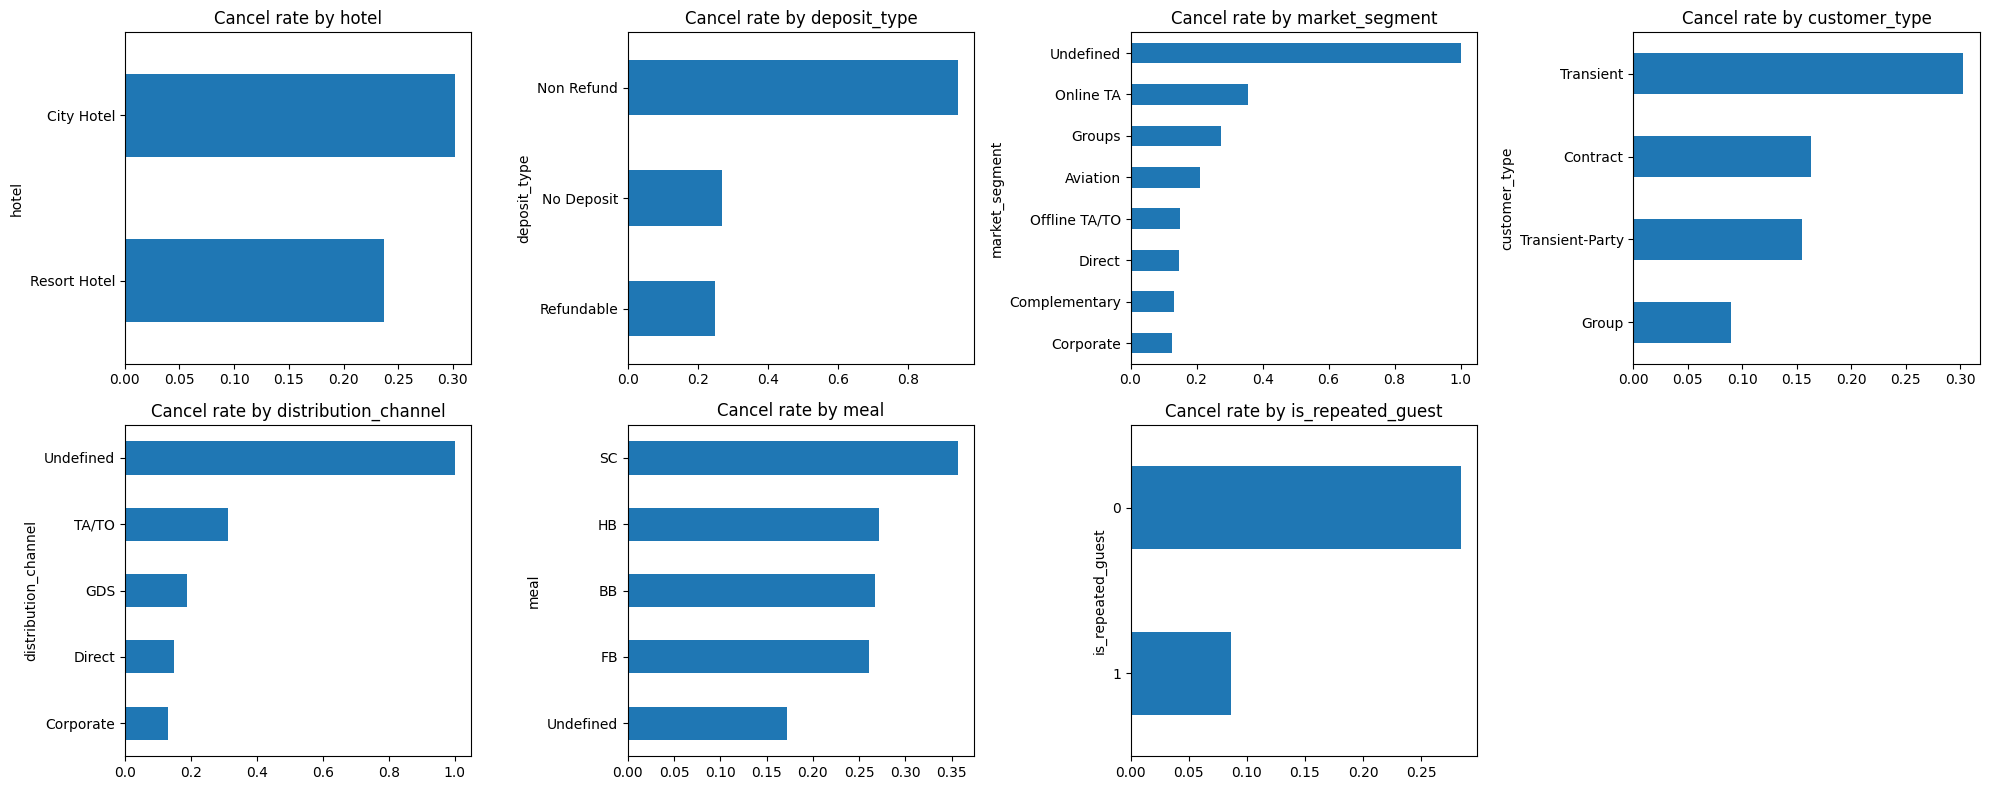

In [9]:
cat_to_check = ["hotel", "deposit_type", "market_segment", "customer_type",
                "distribution_channel", "meal", "is_repeated_guest"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for i, col in enumerate(cat_to_check):
    g = train_df.groupby(col)["is_canceled"].agg(["mean", "count"]).sort_values("mean")
    g["mean"].plot.barh(ax=axes[i], title=f"Cancel rate by {col}")
    print(f"\n{col}\n{g.round(3)}")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

             mean  count
lead_bin                
(-1, 7]     0.086  14345
(7, 30]     0.256  13058
(30, 90]    0.319  18022
(90, 180]   0.352  14551
(180, 365]  0.399   8902
(365, 800]  0.420    431

previous_cancellations
                         mean  count
previous_cancellations              
0                       0.269  67965
1                       0.771   1120
2                       0.326     89
3                       0.260     50
4                       0.247     85

total_of_special_requests
                            mean  count
total_of_special_requests              
0                          0.335  34845
1                          0.226  22942
2                          0.215   9354
3                          0.166   1866
4                          0.096    302

required_car_parking_spaces
                              mean  count
required_car_parking_spaces              
0                            0.302  63500
1                            0.000   5784
2            

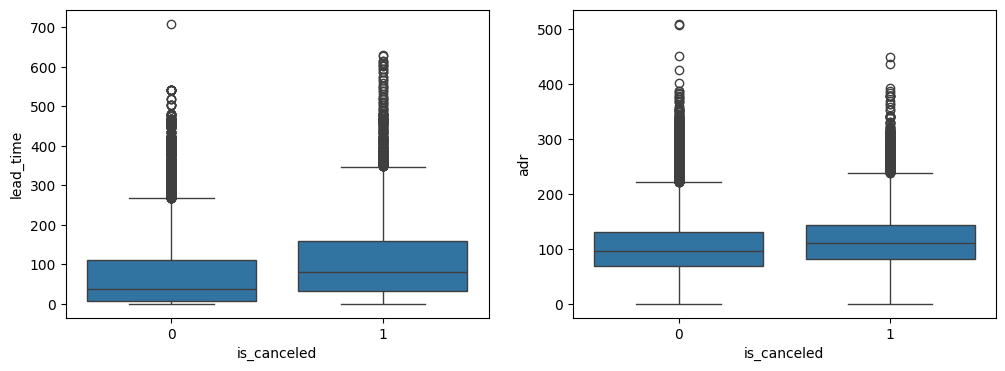

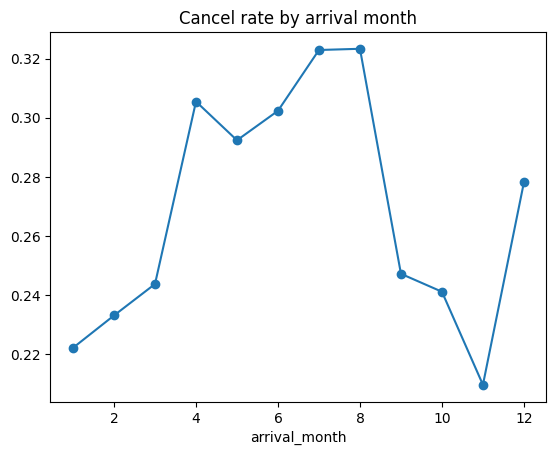

In [10]:
# lead_time في شرايح
train_df["lead_bin"] = pd.cut(train_df["lead_time"], [-1, 7, 30, 90, 180, 365, 800])
print(train_df.groupby("lead_bin", observed=True)["is_canceled"].agg(["mean", "count"]).round(3))

for col in ["previous_cancellations", "total_of_special_requests", "required_car_parking_spaces"]:
    print(f"\n{col}")
    print(train_df.groupby(train_df[col].clip(upper=4))["is_canceled"].agg(["mean", "count"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="is_canceled", y="lead_time", data=train_df, ax=ax[0])
sns.boxplot(x="is_canceled", y="adr", data=train_df, ax=ax[1])
plt.show()

# الإلغاء حسب الشهر
train_df.groupby("arrival_month")["is_canceled"].mean().plot(marker="o", title="Cancel rate by arrival month")
plt.show()

### 6.3 Multivariate
The heatmap and the lead-time × deposit-type table show how features relate to the target and to each other. Strongest linear correlations with `is_canceled` are small (all below 0.19 in absolute value), so the signal comes from combinations of features, which is why tree-based models are expected to do better than a linear one.

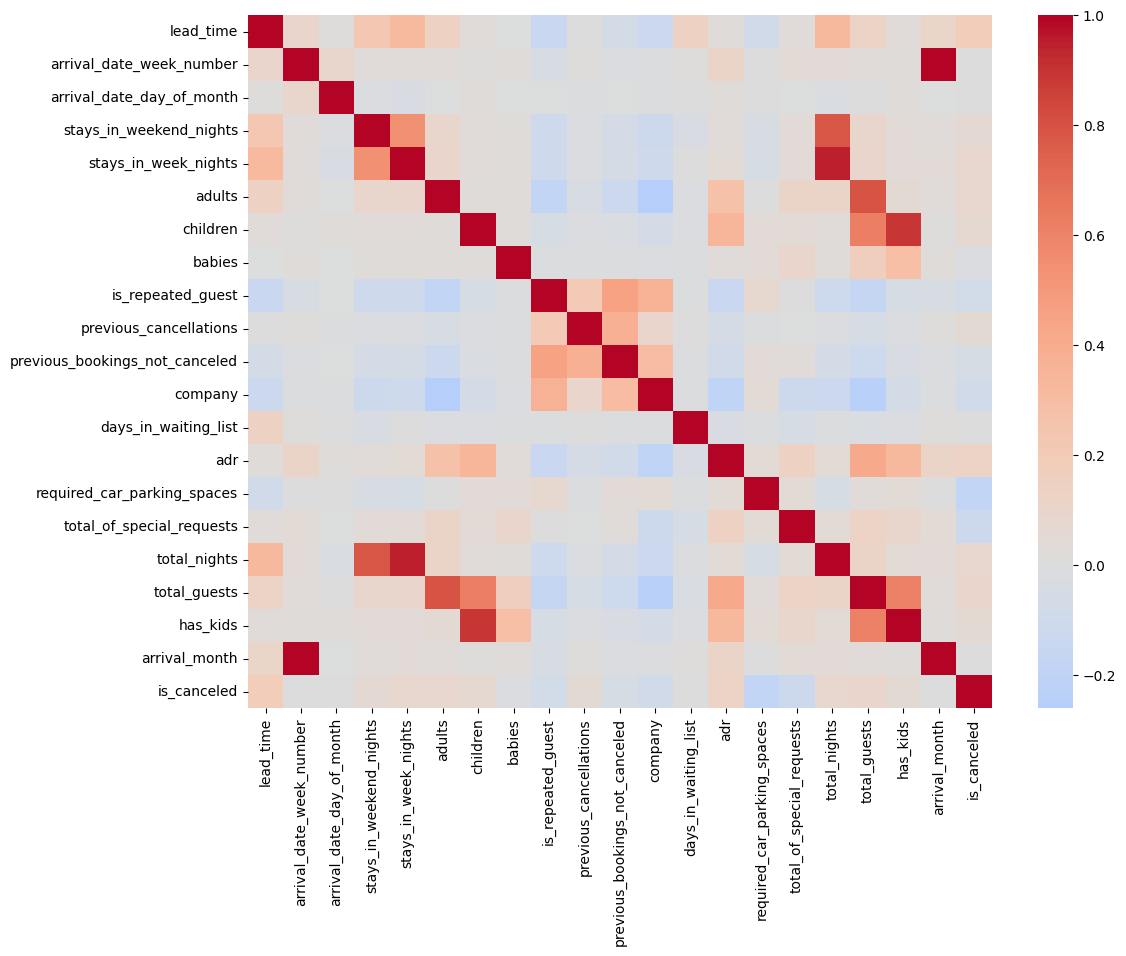

is_canceled                       1.000
lead_time                         0.184
adr                               0.128
total_guests                      0.100
adults                            0.081
total_nights                      0.081
stays_in_week_nights              0.080
children                          0.068
stays_in_weekend_nights           0.056
previous_cancellations            0.053
has_kids                          0.052
days_in_waiting_list              0.008
arrival_month                     0.007
arrival_date_day_of_month         0.006
arrival_date_week_number          0.005
babies                           -0.020
previous_bookings_not_canceled   -0.051
is_repeated_guest                -0.082
company                          -0.093
total_of_special_requests        -0.123
required_car_parking_spaces      -0.185
Name: is_canceled, dtype: float64
lead_bin      (-1, 7]  (7, 30]  (30, 90]  (90, 180]  (180, 365]  (365, 800]
deposit_type                                      

In [11]:
corr = train_df.select_dtypes("number").drop(columns=["lead_bin"], errors="ignore").corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()
print(corr["is_canceled"].sort_values(ascending=False).round(3))

# تفاعل: lead_time مع deposit_type
print(train_df.pivot_table(index="deposit_type", columns="lead_bin",
                           values="is_canceled", aggfunc="mean", observed=True).round(2))

### 6.4 Key insights


1. **Longer lead time → more cancellations.** Cancel rate is 8.6% for bookings made up to 7 days ahead and 39.9% for 180–365 days ahead.
2. **Non-refundable bookings are cancelled almost always (94.3%, 823 bookings), opposite to what you would expect.** The data does not tell us why, so this is reported as an observation and a limitation, not explained.
3. **The booking channel matters.** Online travel agents cancel 35.6% of the time, versus 12.4% for corporate and 14.7% for direct bookings.
4. **Engaged guests cancel less.** Cancel rate falls from 33.5% (no special requests) to 9.6% (4 or more), and repeat guests cancel 8.7% versus 28.4% for first-time guests.
5. **Suspicious pattern:** all 5,806 bookings that required a parking space were *not* cancelled (0.0%). Real behaviour is never that clean; this looks like information recorded after the stay. It is tested in the next section.

*(Optional extra observation: guests with exactly one previous cancellation cancel 77.1% of the time (1,120 bookings), but the rate drops for 2 or more. Mention it without claiming a cause.)*

## 7. Second leakage check: `required_car_parking_spaces`
Insight 5 shows a 0% cancel rate for every booking with a parking request. A cancelled booking probably never gets a parking space recorded, so the hotel would not know this value at booking time.

I compared 5-fold CV on the **training data only** (HistGradientBoosting, same settings):

| | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| with parking | 0.640 | 0.685 | 0.903 | 0.781 |
| without parking | 0.606 | 0.660 | 0.888 | 0.759 |

**Decision:** drop the column and accept the lower, more honest score. The model should only use information the hotel really has when the booking is made.

In [12]:
# Leakage decision from the EDA (section 7): drop the parking column from both sets
parking_cols = ["required_car_parking_spaces"]
X_train = X_train.drop(columns=parking_cols)
X_test = X_test.drop(columns=parking_cols)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (69309, 28) | test: (17328, 28)


## 8. Preprocessing pipeline
A single scikit-learn `ColumnTransformer`, fitted on training data only (and re-fitted inside every CV fold):
- **Numeric:** median imputation → standard scaling
- **Categorical:** most-frequent imputation → one-hot encoding with `min_frequency=30` (rare countries / agents are grouped into one "other" category) and `handle_unknown="ignore"` (so the deployed app does not crash on a new value)

Because the pipeline is part of the model, the same steps are applied automatically in the app.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = X_train.select_dtypes("object").columns.tolist()
print("numeric:", len(num_cols), "| categorical:", len(cat_cols))
print(cat_cols)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore",
                                           min_frequency=30,
                                           sparse_output=False))]), cat_cols),
])

# اختبار إن الـ pipeline شغال (fit على الـ train بس)
Xt = pre.fit_transform(X_train)
print("transformed train shape:", Xt.shape)

numeric: 19 | categorical: 9
['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']
transformed train shape: (69309, 215)


## 9. Models and cross-validation
A baseline plus three algorithms, all compared with the same 5-fold stratified CV on the training set:
- **Baseline:** always predict the majority class
- **Logistic Regression:** simple, interpretable linear model
- **Random Forest:** many decorrelated trees
- **HistGradientBoosting:** boosted trees, fast and strong on tabular data

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
  "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
  "Logistic Regression": LogisticRegression(max_iter=1000),
  "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
  "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"])
    rows.append({"model": name, **{k.replace("test_",""): v.mean() for k, v in s.items() if k.startswith("test_")}})
results = pd.DataFrame(rows).round(3)
results

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Baseline (majority),0.723,0.000,0.000,0.000,0.500,0.277
1,Logistic Regression,0.786,0.664,0.461,0.544,0.830,0.650
2,Random Forest,0.832,0.743,0.599,0.664,0.887,0.758
3,Hist Gradient Boosting,0.827,0.725,0.606,0.660,0.888,0.759


### Results (5-fold CV on the training set)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Baseline (majority) | 0.723 | 0.000 | 0.000 | 0.000 | 0.500 | 0.277 |
| Logistic Regression | 0.786 | 0.664 | 0.461 | 0.544 | 0.830 | 0.650 |
| Random Forest | 0.832 | 0.743 | 0.599 | 0.664 | 0.887 | 0.758 |
| Hist Gradient Boosting | 0.827 | 0.725 | 0.606 | 0.660 | 0.888 | 0.759 |

The baseline reaches 72.3% accuracy just by predicting "not cancelled" for everyone, but its recall and F1 are 0, so accuracy alone is misleading. Logistic Regression raises PR-AUC from 0.277 to 0.650 but catches only 46% of the cancellations. The two tree-based models are clearly better (PR-AUC about 0.76, recall about 0.60), possibly because cancellations depend on combinations of features (lead time, channel, deposit type, country) that a linear model cannot capture. Random Forest and HistGradientBoosting are almost identical, so I chose HistGradientBoosting for its marginally higher PR-AUC.

## 10. Hyperparameter tuning and threshold selection (training data only)
- `RandomizedSearchCV`, 20 random combinations, 5-fold CV, scored by **PR-AUC (average precision)**, which suits an imbalanced target.
- **Threshold:** out-of-fold probabilities on the training set are used to find the threshold that maximises F1. The test set plays no role in choosing it.

**Results:** best parameters: `learning_rate = 0.1`, `max_leaf_nodes = 63`, `max_depth = None`, `l2_regularization = 0.1`. Cross-validated PR-AUC improved from 0.759 to 0.767, a small gain, so the default model was already strong. The threshold that maximises F1 on the out-of-fold training predictions is **0.333**. It is below 0.5, so the model flags risky bookings earlier, which favours recall on the cancelled class.

In [15]:
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve

pipe = Pipeline([("pre", pre), ("model", HistGradientBoostingClassifier(random_state=42))])
params = {
  "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
  "model__max_depth": [None, 6, 10, 15],
  "model__max_leaf_nodes": [31, 63, 127],
  "model__l2_regularization": [0, 0.1, 1.0],
}
search = RandomizedSearchCV(pipe, params, n_iter=20, cv=cv,
                            scoring="average_precision", n_jobs=-1, random_state=42)
search.fit(X_train, y_train)
best = search.best_estimator_
print(search.best_params_, round(search.best_score_, 3))

proba_cv = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(y_train, proba_cv)
f1 = 2*p*r/(p+r+1e-9)
threshold = t[np.argmax(f1[:-1])]
print("threshold:", round(threshold, 3))

{'model__max_leaf_nodes': 63, 'model__max_depth': None, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1} 0.767
threshold: 0.333


## 11. Final evaluation on the untouched test set
The test set is used **once**, with the threshold fixed in the previous section.

**Results on the test set:** recall 0.78, precision 0.64, F1 0.70, ROC-AUC 0.892 and PR-AUC 0.765. These are very close to the cross-validation results (PR-AUC 0.767), so there is no sign of overfitting.

**From the confusion matrix:** of the 4,797 bookings that were really cancelled, 3,729 were caught and 1,068 were missed; 2,089 bookings were flagged although they were not cancelled. In plain words: out of 100 real cancellations the model catches about 78, and out of 100 bookings it flags, about 64 really are cancelled.

              precision    recall  f1-score   support

           0       0.91      0.83      0.87     12531
           1       0.64      0.78      0.70      4797

    accuracy                           0.82     17328
   macro avg       0.77      0.81      0.79     17328
weighted avg       0.83      0.82      0.82     17328

ROC-AUC: 0.892
PR-AUC: 0.765


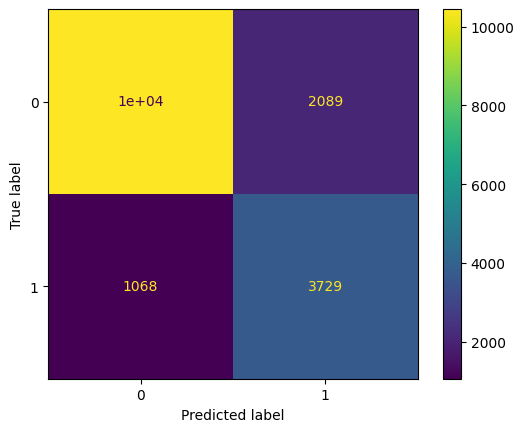

In [16]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC:", round(average_precision_score(y_test, proba), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.show()

## 12. Error analysis and what drives predictions
- **Error rate by market segment:** where does the model make most mistakes? Online TA is the biggest segment, so compare the *rate* and the *count*.
- **Permutation importance** (on the test set, PR-AUC): which features hurt the score most when shuffled.

**Findings:**
- Error rate by market segment: Online TA 22.7% (the largest segment, so it also produces the most mistakes in absolute terms), Aviation 15.7% (a very small group, so not reliable), Direct 14.7%, Corporate 10.4%, Offline TA/TO 10.2%, Groups 9.7%, Complementary 9.4%. Online TA is the hardest segment, possibly because it is a mixed group with a high cancel rate (35.6%).
- The five most important features are **country, lead time, travel agent, special requests and market segment**. Shuffling `country` costs the most PR-AUC (0.170), followed by `lead_time` (0.135), `agent` (0.133), `total_of_special_requests` (0.110) and `market_segment` (0.087).
- `country` and `agent` rank high, but they can act as proxies for habits of these two specific hotels rather than general booking behaviour.

In [17]:
from sklearn.inspection import permutation_importance

errs = X_test.assign(y=y_test, pred=pred)
wrong = errs[errs.y != errs.pred]
print(wrong.groupby("market_segment").size() / errs.groupby("market_segment").size())

imp = permutation_importance(best, X_test, y_test, n_repeats=5,
                             scoring="average_precision", random_state=42, n_jobs=-1)
print(pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10))

market_segment
Aviation         0.156863
Complementary    0.094203
Corporate        0.104271
Direct           0.147414
Groups           0.096838
Offline TA/TO    0.101608
Online TA        0.227251
dtype: float64
country                           0.169651
lead_time                         0.134781
agent                             0.132658
total_of_special_requests         0.109733
market_segment                    0.087131
previous_cancellations            0.056643
customer_type                     0.047731
deposit_type                      0.039908
previous_bookings_not_canceled    0.026573
adr                               0.018643
dtype: float64


## 13. Business recommendation
The probability is turned into three risk levels. The cut-offs below are **a starting point**: cut-offs are chosen with the **training** out-of-fold probabilities, and the **test** table only confirms them.

In [18]:
risk_bins = [0, 0.2, 0.5, 1.0]          # starting point: adjust after looking at the train table
risk_labels = ["Low", "Medium", "High"]

def tier_table(p, y):
    tier = pd.cut(p, risk_bins, labels=risk_labels, include_lowest=True)
    t = (pd.DataFrame({"tier": tier, "cancelled": np.asarray(y)})
           .groupby("tier", observed=True)["cancelled"].agg(n="size", cancel_rate="mean"))
    t["share_of_bookings"] = t["n"] / t["n"].sum()
    return t.round(3)

print("TRAIN (out-of-fold) - use this to choose the cut-offs")
print(tier_table(proba_cv, y_train))
print("\nTEST - confirmation only")
print(tier_table(proba, y_test))

TRAIN (out-of-fold) - use this to choose the cut-offs
            n  cancel_rate  share_of_bookings
tier                                         
Low     36946        0.054              0.533
Medium  15973        0.331              0.230
High    16390        0.727              0.236

TEST - confirmation only
           n  cancel_rate  share_of_bookings
tier                                        
Low     9188        0.053              0.530
Medium  4062        0.329              0.234
High    4078        0.730              0.235


### Recommended policy
The numbers below come from the TEST table above.

| Risk level | Actual cancel rate (test) | Share of bookings | Suggested action |
|---|---|---|---|
| Low (below 20%) | 5.3% | 53.0% | no deposit |
| Medium (20% to 50%) | 32.9% | 23.4% | partial deposit |
| High (50% or more) | 73.0% | 23.5% | full deposit or phone confirmation |

The cut-offs were chosen on the training out-of-fold probabilities and confirmed on the test set: the cancel rate rises clearly from Low to High and is almost identical on train and test. The binary threshold (0.333) is used for the classification report; the 20% and 50% cut-offs are used only for the deposit policy.

### Limitations
- Data comes from two hotels in **Portugal**, not Egypt. Using it for Egyptian hotels would need retraining on local data.
- Data is from **2015–2017**; booking behaviour changes over time. A time-based validation would be a stronger test.
- Non-refundable bookings show a 94% cancel rate, which is unexplained and may reflect how the data was recorded.
- `required_car_parking_spaces` was removed as suspected leakage; `total_of_special_requests` may also be recorded after booking and was kept.
- Duplicate removal is a conservative assumption.
- `country` is a strong feature. Using nationality to decide who pays a deposit could be unfair; a real deployment should review this.
- The threshold reflects an F1 trade-off. A real hotel should set it from its own cost of an empty room versus a refused deposit.

### Next steps
- Validate over time (train on earlier arrivals, test on later ones) to check that the model still works as booking behaviour changes. This needs the arrival year, which was dropped in this version.
- Replace the F1-based threshold with a cost matrix (cost of an empty room versus cost of a refused deposit) from a real hotel.
- Retrain on data from Egyptian hotels, and test whether removing `country` changes the results and improves fairness.

## 14. Save the model for the web app
The full pipeline (preprocessing + model), the threshold, default values and the column order are saved with `joblib`, and loaded by the Streamlit app.

In [19]:
import joblib
defaults = {c: X_train[c].median() for c in num_cols}
defaults.update({c: X_train[c].mode()[0] for c in cat_cols})
joblib.dump({"model": best, "threshold": threshold, "defaults": defaults,
             "columns": X_train.columns.tolist()}, "model.joblib", compress=3)

['model.joblib']

In [20]:
import sklearn, joblib
from google.colab import files
with open("requirements.txt", "w") as f:
    f.write(f"streamlit\npandas\nnumpy\njoblib\nscikit-learn=={sklearn.__version__}\n")
print(open("requirements.txt").read())
files.download("requirements.txt")

streamlit
pandas
numpy
joblib
scikit-learn==1.6.1



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>